**ЛАБОРАТОРНАЯ РАБОТА №2. Гистограммы, профили и проекции**

Выполнили студенты группы 932302: Лебёдкин Владислав и Травкова Ирина

Вариант 6

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

###  Чтение исходного изображения

(np.float64(-0.5), np.float64(739.5), np.float64(739.5), np.float64(-0.5))

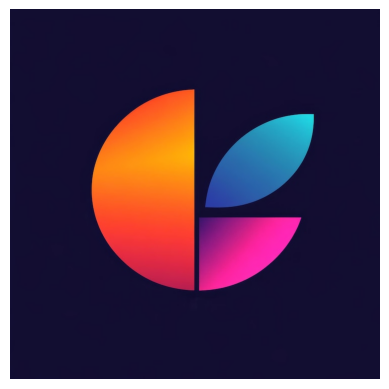

In [2]:
original_image = cv2.imread("abstract.jpg")
changing_image = cv2.cvtColor(original_image,cv2.COLOR_BGR2RGB)
plt.imshow(changing_image)
plt.axis("off")


### 1. Построить гистограмму серого изображения и вычислить дисперсию яркости.

Сначала преобразуем исходное цветное изображение в оттенки серого. Затем с помощью функции `cv2.calcHist()` строим гистограмму распределения яркости пикселей.

Дисперсия показывает, насколько значения яркости отличаются от среднего значения. Для её вычисления используем функцию:

```python
variance = np.var(gray_image)
```

Чем больше дисперсия, тем сильнее различаются светлые и тёмные области изображения.

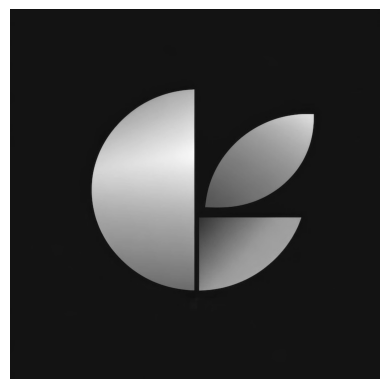

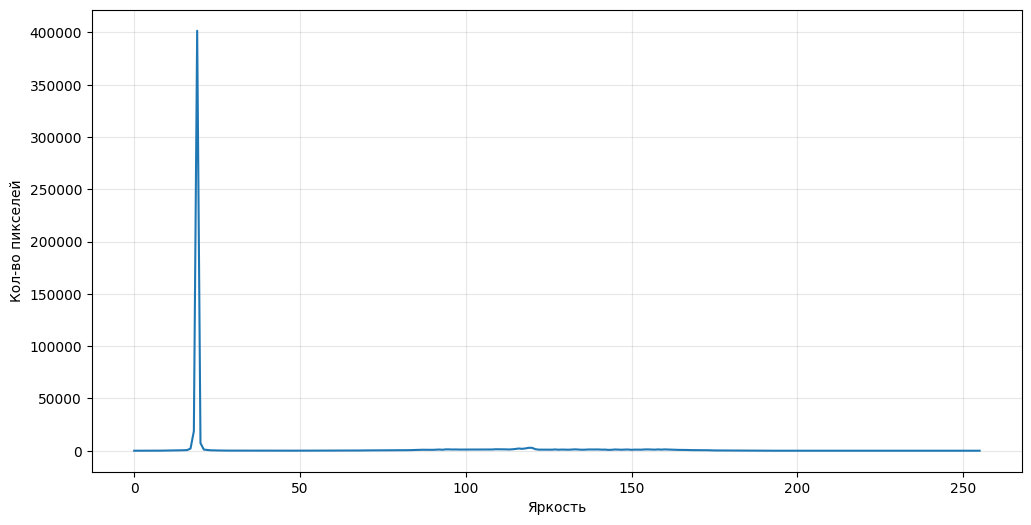

In [3]:
gray_image = cv2.cvtColor(changing_image,cv2.COLOR_RGB2GRAY)
plt.imshow(gray_image, cmap='gray')
plt.axis("off")

gray_hist = cv2.calcHist([gray_image],[0],None,[256],[0,256])
plt.figure(figsize=(12,6))
plt.plot(gray_hist)
plt.xlabel("Яркость")
plt.ylabel("Кол-во пикселей")
plt.grid(True, alpha=0.3)
plt.show()

In [4]:
variance = np.var(gray_image)

print(f'Дисперсия яркости: {variance:.2f}')

Дисперсия яркости: 1893.77


### 2. Построить гистограммы R, G, B и определить наиболее насыщенный канал.

Для цветного изображения отдельно строим гистограммы каналов R, G и B. Каждая гистограмма показывает распределение интенсивности соответствующего цвета.

Среднюю интенсивность канала вычисляем как взвешенное среднее значений его гистограммы:

```python
mean_intensity = (
    np.sum(intensity * rgb_hist.flatten())
    / np.sum(rgb_hist)
)
```

Канал с наибольшей средней интенсивностью считаем наиболее насыщенным в рамках данного задания.

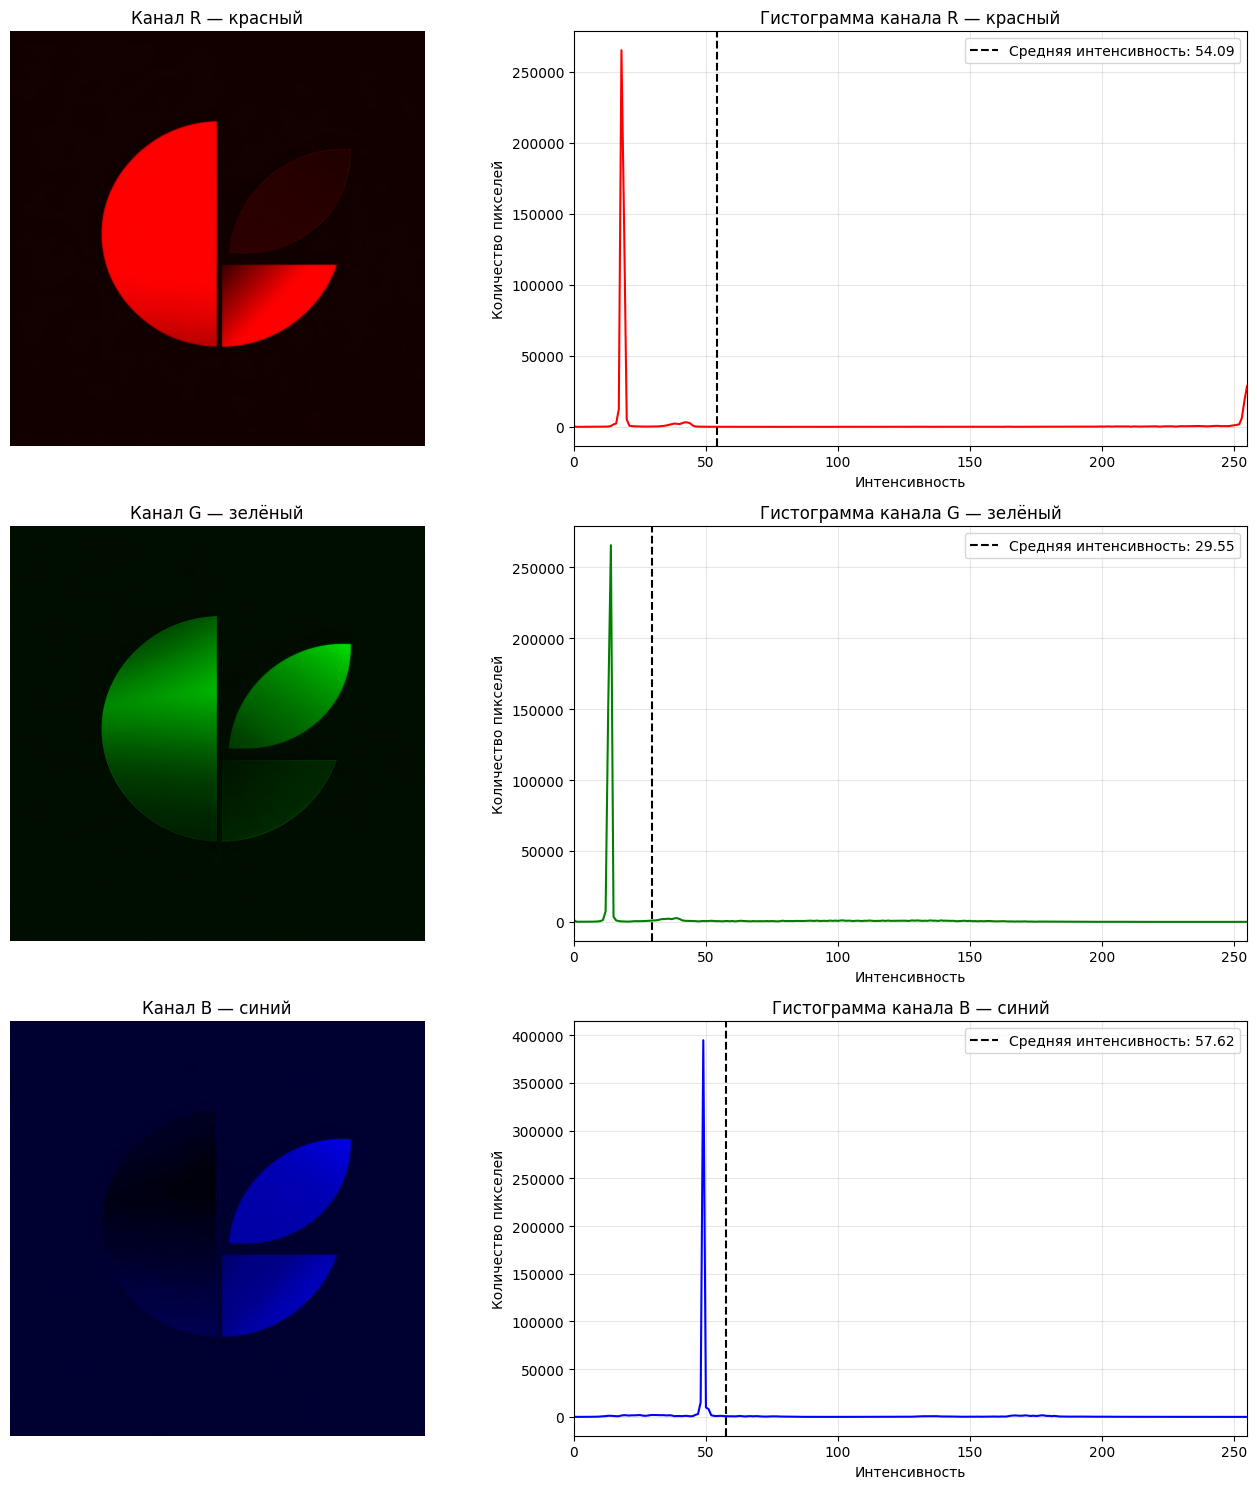

Канал с наибольшей средней интенсивностью: B — синий
Средняя интенсивность: 57.62


In [5]:
channels = ["red", "green", "blue"]
channel_names = ["R — красный", "G — зелёный", "B — синий"]
mean_intensity_value = {}
intensity = np.arange(256)

fig, axes = plt.subplots(3, 2, figsize=(14, 15))

for channel, color in enumerate(channels):
    channel_image = np.zeros_like(changing_image)
    channel_image[:, :, channel] = changing_image[:, :, channel]

    axes[channel, 0].imshow(channel_image)
    axes[channel, 0].set_title(f"Канал {channel_names[channel]}")
    axes[channel, 0].axis("off")

    rgb_hist = cv2.calcHist(
        [changing_image], [channel], None, [256], [0, 256]
    ).flatten()

    mean_intensity = np.sum(intensity * rgb_hist) / np.sum(rgb_hist)
    mean_intensity_value[channel] = mean_intensity

    axes[channel, 1].plot(intensity, rgb_hist, color=color)
    axes[channel, 1].axvline(
        mean_intensity,
        color="black",
        linestyle="--",
        label=f"Средняя интенсивность: {mean_intensity:.2f}"
    )
    axes[channel, 1].set_title(f"Гистограмма канала {channel_names[channel]}")
    axes[channel, 1].set_xlabel("Интенсивность")
    axes[channel, 1].set_ylabel("Количество пикселей")
    axes[channel, 1].set_xlim(0, 255)
    axes[channel, 1].grid(True, alpha=0.3)
    axes[channel, 1].legend()

plt.tight_layout()
plt.show()

max_intensity_channel = max(
    mean_intensity_value, key=mean_intensity_value.get
)

print(
    f"Канал с наибольшей средней интенсивностью: "
    f"{channel_names[max_intensity_channel]}\n"
    f"Средняя интенсивность: "
    f"{mean_intensity_value[max_intensity_channel]:.2f}"
)

### 3. Построить горизонтальный профиль изображения и определить линию с минимальной яркостью.

Горизонтальный профиль изображения показывает изменение средней яркости по строкам. Для каждой строки вычисляем среднее значение всех находящихся в ней пикселей:

```python
horizontal_profile = np.mean(gray_image, axis=1)
```

Чтобы определить строку с минимальной средней яркостью, используем:

```python
min_row_idx = np.argmin(horizontal_profile)
```

Полученный индекс `min_row_idx` соответствует номеру самой тёмной строки изображения.

 Строка с минимальной яркостью: 571 


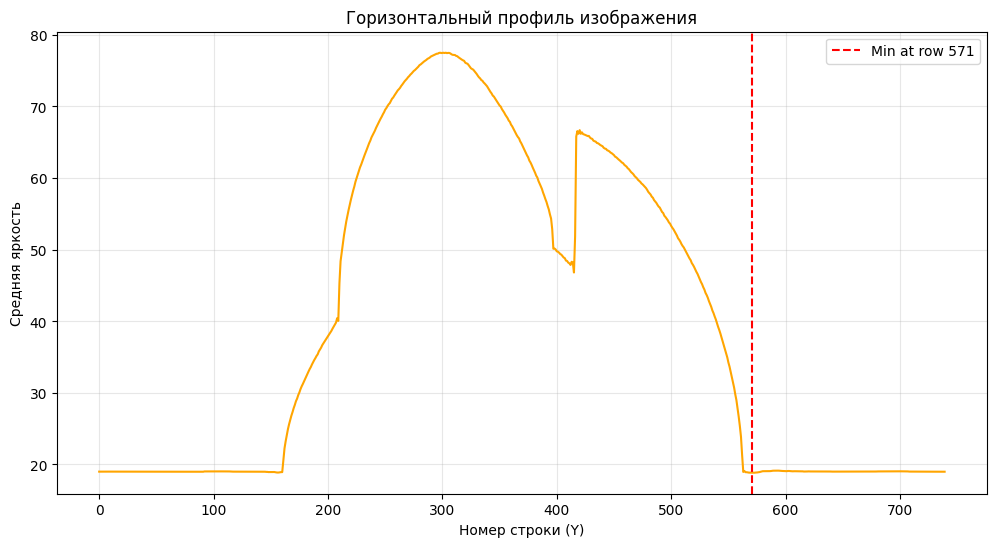

In [6]:
height, width = gray_image.shape

horizontal_profile = np.mean(gray_image,axis=1)

print(f' Строка с минимальной яркостью: {np.argmin(horizontal_profile)} ')

plt.figure(figsize=(12, 6))
plt.plot(horizontal_profile, color='orange')
plt.axvline(x=np.argmin(horizontal_profile), color='red', linestyle='--', label=f'Min at row {np.argmin(horizontal_profile)}')
plt.title('Горизонтальный профиль изображения')
plt.xlabel('Номер строки (Y)')
plt.ylabel('Средняя яркость')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### 4.Построить вертикальную проекцию изображения и определить линию с максимальной яркостью.

**Вертикальная проекция** — это сумма интенсивностей пикселей по каждому столбцу изображения (``axis=0``). 

Для поиска линии с максимальной яркостью находим столбец с максимальным значением проекции:
```python
max_col_idx = np.argmax(vertical_projection)
```

 Столбец с максимальной яркостью: 367


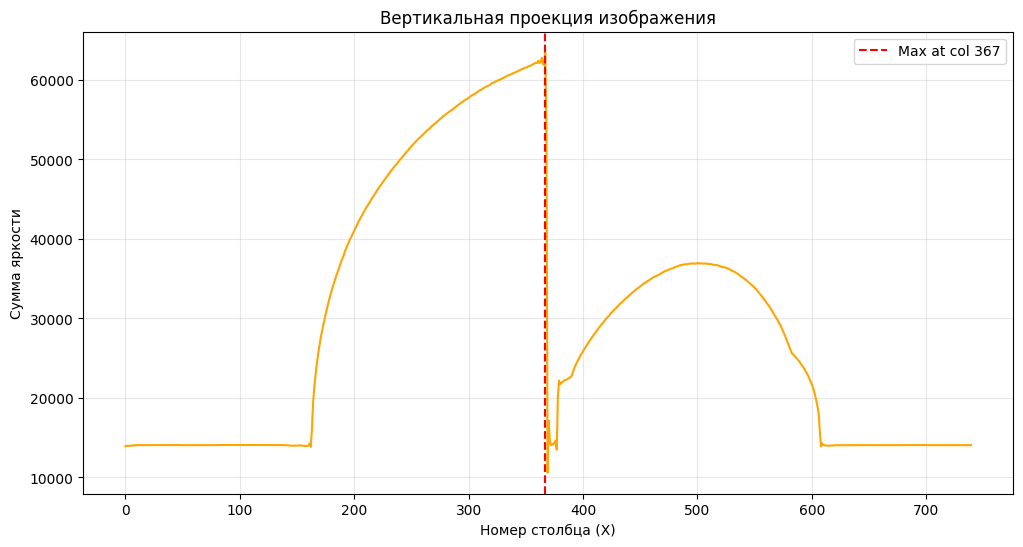

In [7]:
# построение вертикальной проекции
vertical_projection = np.sum(gray_image, axis=0)

# поиск столбца с максимальной яркостью
max_col_idx = np.argmax(vertical_projection)
max_proj_val = vertical_projection[max_col_idx]

print(f' Столбец с максимальной яркостью: {max_col_idx}')

plt.figure(figsize=(12, 6))
plt.plot(vertical_projection, color='orange')
plt.axvline(x=max_col_idx, color='red', linestyle='--', label=f'Max at col {max_col_idx}')
plt.title('Вертикальная проекция изображения')
plt.xlabel('Номер столбца (X)')
plt.ylabel('Сумма яркости')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### 5.Построить горизонтальные и вертикальные проекции бинарного изображения и найти границы объектов.

Сначала выполним бинаризацию изображения. Применяем метод Оцу для автоматического выбора порога: ``_, binary = cv2.threshold(gray_image, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)``

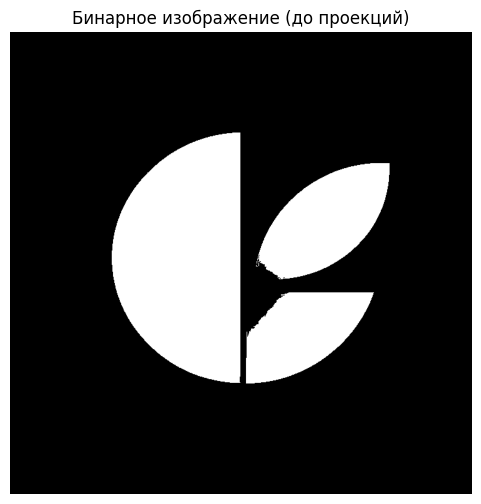

In [8]:
# Бинаризация методом Оцу
_, binary = cv2.threshold(gray_image, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
plt.figure(figsize=(6,6))
plt.imshow(binary, cmap='gray')
plt.title("Бинарное изображение (до проекций)")
plt.axis('off')
plt.show()

Теперь построим проекции и найдём границы объекта. Для построения горизонтальной и вертикальной проекций считаем сумму белых пикселей (255) по строкам и столбцам соответственно. Для поиска границ объекта находим строки и столбцы, где проекция > 0 (есть белые пиксели):
- Верхняя граница: первая строка с объектом (**y_min**)
- Нижняя граница: последняя строка с объектом (**y_max**)
- Левая граница: первый столбец с объектом (**x_min**)
- Правая граница: последний столбец с объектом (**x_max**)

Координаты (x_min, y_min) и (x_max, y_max) задают минимальный прямоугольник, содержащий все белые пиксели объекта.

In [9]:
# Горизонтальная и вертикальная проекции бинарного изображения
h_proj_bin = np.sum(binary, axis=1)
v_proj_bin = np.sum(binary, axis=0)

# Поиск границ объектов (первые и последние ненулевые значения)
rows_with_obj = np.where(h_proj_bin > 0)[0]
cols_with_obj = np.where(v_proj_bin > 0)[0]

if len(rows_with_obj) > 0:
    y_min, y_max = rows_with_obj[0], rows_with_obj[-1]
    print(f' Границы объекта по вертикали: строки {y_min} – {y_max} (высота = {y_max - y_min + 1})')
else:
    print(' Объекты не найдены')

if len(cols_with_obj) > 0:
    x_min, x_max = cols_with_obj[0], cols_with_obj[-1]
    print(f' Границы объекта по горизонтали: столбцы {x_min} – {x_max} (ширина = {x_max - x_min + 1})')
else:
    print(' Объекты не найдены')

 Границы объекта по вертикали: строки 161 – 562 (высота = 402)
 Границы объекта по горизонтали: столбцы 163 – 607 (ширина = 445)


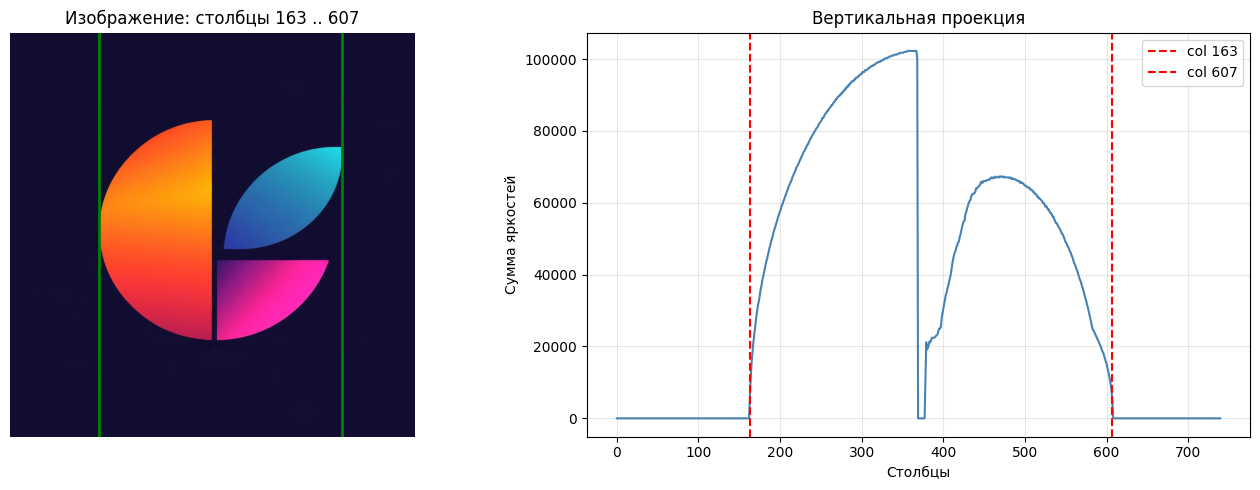

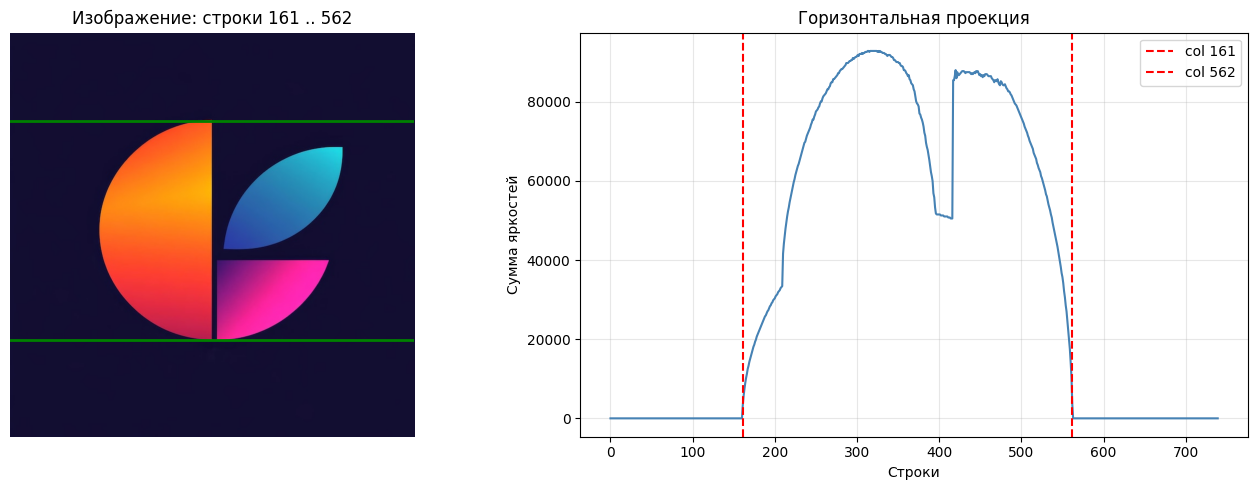

In [10]:
# Визуализация вертикальной проекции
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Левый график: Изображение с границами
ax1.imshow(changing_image)
ax1.axvline(x_min, color='green', linewidth=2)
ax1.axvline(x_max, color='green', linewidth=2)
ax1.set_title(f'Изображение: столбцы {x_min} .. {x_max}')
ax1.axis('off')

# Правый график: Вертикальная проекция
ax2.plot(v_proj_bin, color='steelblue', linewidth=1.5)
ax2.axvline(x_min, color='red', linestyle='--', label=f'col {x_min}')
ax2.axvline(x_max, color='red', linestyle='--', label=f'col {x_max}')
ax2.set_title('Вертикальная проекция')
ax2.set_xlabel('Столбцы')
ax2.set_ylabel('Сумма яркостей')
ax2.legend(loc='upper right')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Визуализация горизонтальной проекции
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Левый график: Изображение с границами
ax1.imshow(changing_image)
ax1.axhline(y_min, color='green', linewidth=2)
ax1.axhline(y_max, color='green', linewidth=2)
ax1.set_title(f'Изображение: строки {y_min} .. {y_max}')
ax1.axis('off')

# Правый график: Горизонтальная проекция
ax2.plot(h_proj_bin, color='steelblue', linewidth=1.5)
ax2.axvline(y_min, color='red', linestyle='--', label=f'col {y_min}')
ax2.axvline(y_max, color='red', linestyle='--', label=f'col {y_max}')
ax2.set_title('Горизонтальная проекция')
ax2.set_xlabel('Строки')
ax2.set_ylabel('Сумма яркостей')
ax2.legend(loc='upper right')
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

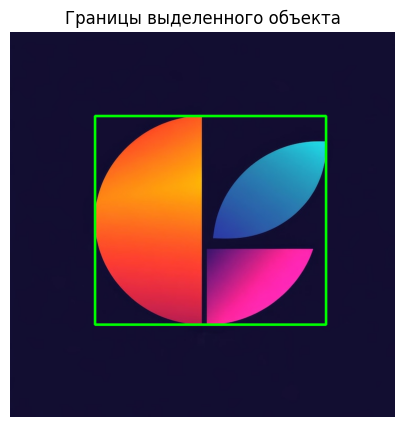

In [11]:
# Отображение бинарного изображения с рамкой границ
img_bound = original_image.copy()
if len(rows_with_obj) > 0 and len(cols_with_obj) > 0:
    cv2.rectangle(img_bound, (x_min, y_min), (x_max, y_max), (0, 255, 0), 3)
    plt.figure(figsize=(8, 5))
    plt.imshow(cv2.cvtColor(img_bound, cv2.COLOR_BGR2RGB))
    plt.title('Границы выделенного объекта')
    plt.axis('off')
    plt.show()

**Ответы на контрольные вопросы:**
1. **Что такое гистограмма изображения и для чего она используется?** Гистограмма изображения — это график, показывающий распределение интенсивностей (яркости) пикселей. По оси X откладываются уровни яркости (от 0 до 255), а по оси Y — количество пикселей, имеющих данную яркость. Используется для оценки яркости, контраста, экспозиции изображения и выбора оптимального порога бинаризации.
2. **Чем отличается гистограмма цветного изображения от серого?** Для изображения в градациях серого строится одна гистограмма, которая показывает общее распределение яркости всех пикселей. Для цветного изображения строятся три отдельные гистограммы для каждого цветового канала, показывающие распределение интенсивности конкретного цвета.
3. **Что такое профиль изображения?** Профиль изображения — это одномерный массив (график), который показывает изменение средней интенсивности пикселей вдоль определенной оси (по строкам или по столбцам). Он позволяет выявлять наличие горизонтальных или вертикальных структур (например, полос или линий) на изображении.
4. **Как вычисляется горизонтальный и вертикальный профиль?** Горизонтальный профиль: вычисляется как среднее арифметическое значение яркости пикселей в каждой строке изображения. Вертикальный профиль: вычисляется как среднее арифметическое значение яркости пикселей в каждом столбце изображения.
5. **Что такое проекция изображения?** Проекция изображения — это одномерный массив, полученный путем суммирования интенсивностей пикселей вдоль определенной оси (по строкам или по столбцам).
6. **В чём разница между профилем и проекцией изображения?** Главная разница заключается в математической операции. Профиль использует операцию усреднения (mean). Он показывает среднюю яркость в строке/столбце и не зависит от размера объекта. Проекция использует операцию суммирования (sum). Она показывает общую сумму яркостей (или количество белых пикселей на бинарном изображении) и напрямую зависит от размера объекта в данной строке/столбце.
7. **Как гистограмма помогает в улучшении контраста изображения?** Гистограмма показывает, какой диапазон яркостей используется. Если график узкий и сосредоточен в центре, изображение имеет низкий контраст. Метод эквализации (выравнивания) гистограммы перераспределяет значения пикселей так, чтобы они равномерно заполнили весь доступный диапазон от 0 до 255. Это делает темные области темнее, а светлые — светлее, визуально увеличивая контраст.
8. **Как можно использовать горизонтальные и вертикальные проекции бинарного изображения?** На бинарном изображении (где объект = 255, фон = 0) проекции показывают количество белых пикселей в каждой строке или столбце. Это используется для: поиска точных координат границ объектов, выделения строк и столбцов текста при распознавании документов, определения наличия или отсутствия объекта в кадре.
9. **Как изменится гистограмма изображения после применения фильтра сглаживания?** Фильтры сглаживания устраняют резкие перепады яркости и шум. На гистограмме пики могут стать ниже, шире или объединиться.
10. **Что показывает пик на гистограмме изображения?** Пик на гистограмме показывает количество пикселей в изображении, которые имеют конкретное значение интенсивности (яркости или цвета). Чем выше пик, тем больше пикселей такого оттенка присутствует на картинке (например, высокий пик около 255 означает наличие большой светлой области или фона).